# Analyse du delta hedging — banc d'essai visuel

**But** : les tests disent seulement « oui / non ». Ici on veut voir **à quel point** une couverture marche,
avec des chiffres et des graphes qu'on réutilisera pour chaque modèle (Black-Scholes aujourd'hui,
Heston et spreads plus tard).

**Plan du notebook** (une figure = une question)

| Fig. | Question |
|---|---|
| **1** | Comment se répartissent les P&L, et se resserrent-ils quand on rebalance plus souvent ? |
| 2 | L'erreur tend-elle vers 0 (pente $-1/2$ en échelle log) ? *(à venir)* |
| 3 | Un chemin dans le temps : option vs portefeuille de couverture *(à venir)* |
| 4 | Vol mal estimée : combien perd-on ? *(à venir)* |
| 5 | Même test sur données réelles *(à venir)* |

Pour l'instant : **figure 1 seulement**.

## 0. Paramètres

Les mêmes que dans `tests/test_hedging.py` : la banque **vend** un call à la monnaie d'un an et le couvre avec
le delta de Black-Scholes.

$$S_0 = 100,\quad K = 100,\quad T = 1 \text{ an},\quad r = 3\%,\quad \sigma = 20\%$$

Les chemins sont simulés avec la **même** vol $\sigma = 20\%$ que le modèle : le modèle est « juste ».
Seule source d'erreur : on ne rebalance pas en continu.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spread_options.analytics import bs_call, bs_delta
from spread_options.hedging import delta_hedge_pnl
from spread_options.models import simulate_gbm_paths
from spread_options.products import call_payoff

S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.03, 0.2
price0 = bs_call(S0, K, T, r, sigma)                                # what the client pays us
delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma) # rule Delta(S, tau)
payoff_fn = lambda ST: call_payoff(ST, K)

print(f"price0 = {price0:.2f}")

price0 = 9.41


## 1. On couvre 4 fois, avec des fréquences différentes

Même expérience que le test, répétée pour $n = 4$ (trimestriel), $12$ (mensuel), $52$ (hebdo), $252$ (quotidien)
rebalancements, sur 1000 chemins chacune.

- `obs_times` : les $n+1$ dates $0, T/n, 2T/n, \dots, T$
- `results[n]` : un tableau de 1000 P&L finaux (un par chemin)

⏱ ~12 s (boucle `for` simple dans `hedge_one_path`).

In [2]:
results = {} # key = number of rebalancings, value = 1000 P&L
for n_steps in [4, 12, 52, 252]: # quarterly, monthly, weekly, daily
    obs_times = np.linspace(0, T, n_steps + 1)
    paths = simulate_gbm_paths(S0, r, sigma, obs_times, n_paths=1000)
    results[n_steps] = delta_hedge_pnl(paths, T, r, price0, delta_fn, payoff_fn)

## 2. Les 4 indicateurs

On les gardera pour **tout** le projet :

| Indicateur | Ce qu'il mesure | Ce qu'on attend si le modèle est juste |
|---|---|---|
| **Moyenne** | le prix est-il juste ? | $\approx 0$ |
| **Écart-type** | qualité de la couverture | petit, et $\to 0$ quand $n \to \infty$ |
| **Écart-type / prix** | idem, sans unité (pour comparer un call à 9 \$ et un spread à 3 \$) | quelques % |
| **Pire 5 %** (quantile 5 %) | la perte dépassée 1 fois sur 20 | proche de 0 |

In [3]:
for n, pnl in results.items():
    print(f"{n:>4} rebal. | mean {pnl.mean():6.3f} | std {pnl.std():5.2f} "
          f"| std/price {pnl.std() / price0:5.1%} | worst 5% {np.quantile(pnl, 0.05):6.2f}")

   4 rebal. | mean -0.080 | std  3.37 | std/price 35.8% | worst 5%  -5.79
  12 rebal. | mean  0.001 | std  1.92 | std/price 20.4% | worst 5%  -3.38
  52 rebal. | mean  0.057 | std  0.94 | std/price 10.0% | worst 5%  -1.43
 252 rebal. | mean  0.017 | std  0.46 | std/price  4.8% | worst 5%  -0.67


## 3. Figure 1 : histogramme des P&L

Un histogramme compte combien de chemins tombent dans chaque petit intervalle de P&L.
- mêmes `bins` pour les 4 courbes → elles sont comparables
- `histtype="step"` → seulement le contour, sinon les couleurs se cachent

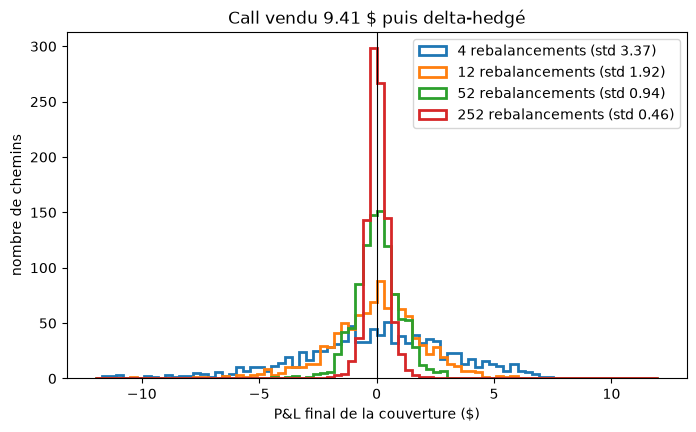

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(-12, 12, 81) # same bins for all curves, so they can be compared
for n, pnl in results.items():
    ax.hist(pnl, bins=bins, histtype="step", linewidth=2, # "step" = outline only, curves stay readable
            label=f"{n} rebalancements (std {pnl.std():.2f})")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("P&L final de la couverture ($)")
ax.set_ylabel("nombre de chemins")
ax.set_title(f"Call vendu {price0:.2f} $ puis delta-hedgé")
ax.legend()
plt.show()

## 4. Ce qu'on lit

- Les 4 cloches sont **centrées sur 0** : en moyenne la banque ne gagne ni ne perd → le **prix** 9,41 est juste.
- Plus on rebalance, plus la cloche est **fine** : la **couverture** est meilleure.
- Rebalancer **4 fois plus souvent** (12 → 52 → 252) **divise l'écart-type par ≈ 2** : loi en $1/\sqrt{n}$
  (expliquée et vérifiée en figure 2).
- Même au quotidien, il reste un écart-type ≈ 5 % du prix : c'est le coût de ne pas couvrir en continu.

**Pour la suite du projet** : avec Heston couvert par le delta de Black-Scholes, ou un spread couvert par une
approximation, on regardera si la cloche reste centrée (prix juste ?) et si elle continue à se resserrer (couverture
juste ?). Si l'écart-type **cesse de baisser** quand $n$ augmente, c'est le **modèle** qui est en cause.
